In [5]:
# -------------------------------------------------------------
# 0. Imports & Working Directory
# -------------------------------------------------------------
import pandas as pd
import numpy as np
import os

r = r'C:\CNN-DGA'
os.chdir(r)

# Load dataset
dga = pd.read_csv('dga-dataset.txt', sep=',', header=None)
dga.columns = ['label', 'origin', 'domain']


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_curve, auc,
    precision_recall_curve, average_precision_score
)
import seaborn as sns
import matplotlib.pyplot as plt
import pickle

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, Conv1D, GlobalMaxPooling1D, Dense,
    Dropout, BatchNormalization
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.regularizers import l2

# -------------------------------------------------------------
# 2. Parameters
# -------------------------------------------------------------
MAXLEN = 75
MAX_VOCAB = 40
EMBED_DIM = 128
BATCH_SIZE = 128
EPOCHS = 10

# -------------------------------------------------------------


In [7]:
# 3. Preprocessing
# -------------------------------------------------------------
X = dga['domain'].astype(str).str.lower().values

# Label map
label_map = {label: idx for idx, label in enumerate(dga['label'].unique())}
print("Label mapping:", label_map)
y = dga['label'].map(label_map).values

# char-level tokenizer
char_texts = [" ".join(list(x)) for x in X]

tok = Tokenizer(
    num_words=MAX_VOCAB,
    char_level=False,
    filters="",
    lower=False,
    oov_token="<OOV>"
)
tok.fit_on_texts(char_texts)

seqs = tok.texts_to_sequences(char_texts)
X_pad = pad_sequences(seqs, maxlen=MAXLEN, padding='post', truncating='post')

# -------------------------------------------------------------
# 4. Train/Test Split
# -------------------------------------------------------------
# First split: TRAIN + TEST
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X_pad, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second split: TRAIN + VALIDATION
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.20,
    random_state=42,
    stratify=y_train_full
)

print("Train samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))
print("Batches per epoch:", len(X_train) // BATCH_SIZE)

# -------------------------------------------------------------
# 5. CNN Model
# -------------------------------------------------------------
vocab_size = min(MAX_VOCAB, len(tok.word_index) + 1)

model = Sequential([
    Embedding(input_dim=vocab_size + 1, output_dim=EMBED_DIM, input_length=MAXLEN),

    Conv1D(128, 3, activation='relu', padding='same', kernel_regularizer=l2(0.001)),
    BatchNormalization(),

    Conv1D(128, 5, activation='relu', padding='same', kernel_regularizer=l2(0.001)),
    GlobalMaxPooling1D(),

    Dropout(0.5),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.3),

    Dense(1, activation='sigmoid')
])

model.compile(optimizer=Adam(1e-3), loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Label mapping: {'dga': 0, 'legit': 1}
Train samples: 431934
Validation samples: 107984
Test samples: 134980
Batches per epoch: 3374


c:\CNN-DGA\venv\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_1          │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
class CleanEpochOutput(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}

        # Pick whatever accuracy key exists
        acc = logs.get("accuracy") or logs.get("binary_accuracy")
        val_acc = logs.get("val_accuracy") or logs.get("val_binary_accuracy")

        # Now print
        print(
            f"Epoch {epoch+1}/{EPOCHS} — "
            f"loss: {logs['loss']:.4f} — "
            f"acc: {acc:.4f} — "
            f"val_loss: {logs['val_loss']:.4f} — "
            f"val_acc: {val_acc:.4f}"
        )
clean_output = CleanEpochOutput()

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    callbacks=[es, clean_output],
    verbose=0    # << HIDE ALL STEPS/BATCHES
)




In [ ]:
# 7. Evaluation on Test Set
# -------------------------------------------------------------
y_pred_proba = model.predict(X_test).ravel()
y_pred = (y_pred_proba >= 0.5).astype(int)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, digits=4))

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"Confusion Matrix: TN={tn}, FP={fp}, FN={fn}, TP={tp}")

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

test_accuracy = accuracy_score(y_test, y_pred)
test_precision = precision_score(y_test, y_pred)
test_recall = recall_score(y_test, y_pred)
test_f1 = f1_score(y_test, y_pred)
test_auc = roc_auc_score(y_test, y_pred_proba)

print("\n--- Test Metrics ---")
print(f"Accuracy:  {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"F1 Score:  {test_f1:.4f}")
print(f"AUC:       {test_auc:.4f}")

# -------------------------------------------------------------
# 8. Visualizations
# -------------------------------------------------------------
plt.style.use("seaborn-v0_8-darkgrid")

# LOSS Curve
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='Train Loss', linewidth=2)
plt.plot(history.history['val_loss'], label='Val Loss', linewidth=2)
plt.title("Loss Curve")
plt.legend()

# ACCURACY Curve
plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Train Acc', linewidth=2)
plt.plot(history.history['val_accuracy'], label='Val Acc', linewidth=2)
plt.title("Accuracy Curve")
plt.legend()
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}", linewidth=2)
plt.plot([0,1], [0,1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

# Precision-Recall Curve
prec, rec, _ = precision_recall_curve(y_test, y_pred_proba)
ap = average_precision_score(y_test, y_pred_proba)

plt.figure()
plt.plot(rec, prec, linewidth=2)
plt.title(f"Precision-Recall Curve (AP={ap:.4f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.show()

# Confusion Matrix Heatmap
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues",
            xticklabels=["Benign","DGA"],
            yticklabels=["Benign","DGA"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# -------------------------------------------------------------
# 9. Save Model & Tokenizer
# -------------------------------------------------------------
model.save("cnn_dga_model.h5")
with open("cnn_tokenizer.pkl", "wb") as f:
    pickle.dump(tok, f)

print("Model and tokenizer saved.")

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_7 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_14 (Conv1D)              │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_15 (Conv1D)              │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_7          │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
4219/4219 ━━━━━━━━━━━━━━━━━━━━ 204s 48ms/step - accuracy: 0.8946 - loss: 0.3564
Epoch 2/10
4219/4219 ━━━━━━━━━━━━━━━━━━━━ 208s 49ms/step - accuracy: 0.9187 - loss: 0.2700
Epoch 3/10
4219/4219 ━━━━━━━━━━━━━━━━━━━━ 206s 49ms/step - accuracy: 0.9243 - loss: 0.2554
Epoch 4/10
4219/4219 ━━━━━━━━━━━━━━━━━━━━ 206s 49ms/step - accuracy: 0.9278 - loss: 0.2459
Epoch 5/10
4219/4219 ━━━━━━━━━━━━━━━━━━━━ 210s 50ms/step - accuracy: 0.9305 - loss: 0.2391
Epoch 6/10
4219/4219 ━━━━━━━━━━━━━━━━━━━━ 211s 50ms/step - accuracy: 0.9326 - loss: 0.2338
Epoch 7/10
4219/4219 ━━━━━━━━━━━━━━━━━━━━ 200s 47ms/step - accuracy: 0.9342 - loss: 0.2306
Epoch 8/10
4219/4219 ━━━━━━━━━━━━━━━━━━━━ 200s 47ms/step - accuracy: 0.9349 - loss: 0.2269
Epoch 9/10
4219/4219 ━━━━━━━━━━━━━━━━━━━━ 204s 48ms/step - accuracy: 0.9357 - loss: 0.2250
Epoch 10/10
4219/4219 ━━━━━━━━━━━━━━━━━━━━ 201s 48ms/step - accuracy: 0.9364 - loss: 0.2239


4219/4219 ━━━━━━━━━━━━━━━━━━━━ 18s 4ms/step

Classification Report:
              precision    recall  f1-score   support

           0     0.9567    0.9449    0.9508     67500
           1     0.9455    0.9572    0.9513     67480

    accuracy                         0.9511    134980
   macro avg     0.9511    0.9511    0.9511    134980
weighted avg     0.9511    0.9511    0.9511    134980

Confusion Matrix: TN=63780, FP=3720, FN=2887, TP=64593

--- Test Metrics ---
Accuracy:  0.9511
Precision: 0.9455
Recall:    0.9572
F1 Score:  0.9513
AUC:       0.9892


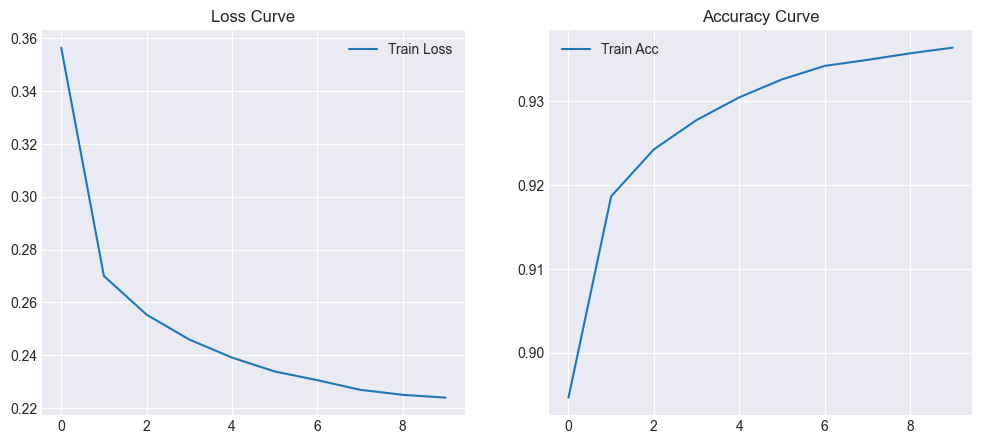

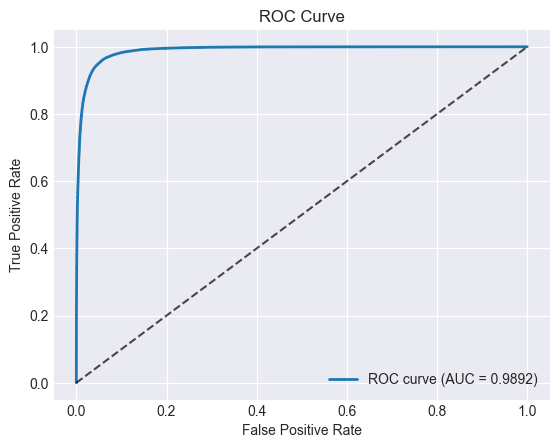

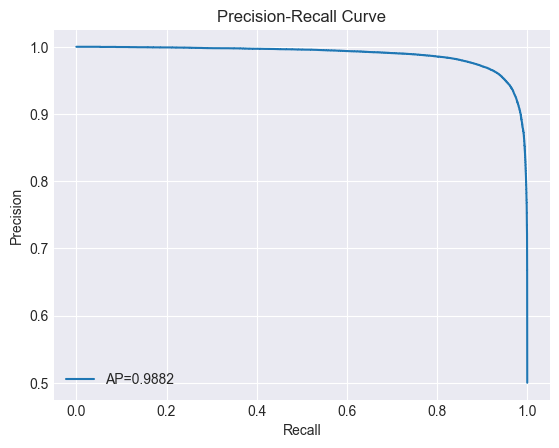

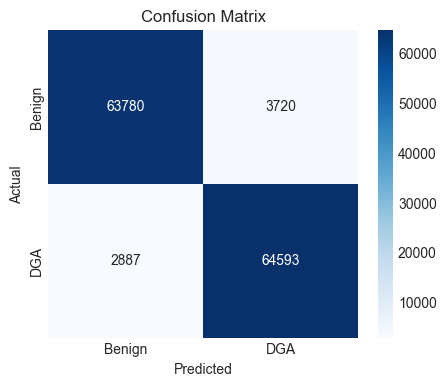

Model and tokenizer saved.
